In [ ]:
import os
import shutil
import random
from pathlib import Path
from create_missing_masks import create_missing_masks,verify_mask_creation

# Set seed for reproducibility
random.seed(42)

In [221]:
import os
from pathlib import Path
from PIL import Image
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as T
import torch


class SegmentationDataset(Dataset):
    def __init__(self, images_dir, masks_dir, transform=None, target_transform=None):
        self.images_dir = Path(images_dir)
        self.masks_dir = Path(masks_dir)
        self.image_files = sorted([f for f in self.images_dir.iterdir() if f.suffix in ['.jpg', '.png', '.jpeg']])
        self.mask_files = [self.masks_dir / (img.stem + '.png') for img in self.image_files]

        self.transform = transform
        self.target_transform = target_transform

    def __len__(self):
        return len(self.image_files)

    def __getitem__(self, idx):
        img_path = self.image_files[idx]
        mask_path = self.mask_files[idx]

        image = Image.open(img_path).convert('RGB')
        mask = Image.open(mask_path).convert('L')  # For grayscale masks (single channel)

        if self.transform:
            image = self.transform(image)
        if self.target_transform:
            mask = self.target_transform(mask)

        return image, mask


# === Define paths ===
root_dir = Path("data")

train_images_dir = root_dir / "JPEGImages/train"
train_masks_dir = root_dir / "SegmentationClass/train"

val_images_dir = root_dir / "JPEGImages/val"
val_masks_dir = root_dir / "SegmentationClass/val"

# === Transforms ===
transform = T.Compose([
    T.RandomRotation(degrees=15),  # Randomly rotates the image by up to +/- 15 degrees
    T.RandomHorizontalFlip(p=0.5), # Randomly flips the image horizontally with 50% probability
    T.RandomVerticalFlip(p=0.1),   # Optionally, add random vertical flip with a lower probability
    T.ColorJitter(contrast=0.2),   # Randomly changes the contrast by up to +/- 20%
    T.ToTensor()
])

target_transform = T.Compose([
    T.ToTensor()
])

# === Datasets ===
train_dataset = SegmentationDataset(train_images_dir, train_masks_dir, transform, target_transform)
val_dataset = SegmentationDataset(val_images_dir, val_masks_dir, transform, target_transform)

# === Dataloaders ===
train_loader = DataLoader(train_dataset, batch_size=4, shuffle=True, num_workers=4)
val_loader = DataLoader(val_dataset, batch_size=4, shuffle=False, num_workers=4)



In [121]:
import torch
import torch.nn as nn
import torch.nn.functional as F

class UNet(nn.Module):
    def __init__(self, in_channels=3, out_channels=1):
        super(UNet, self).__init__()

        def conv_block(in_c, out_c):
            return nn.Sequential(
                nn.Conv2d(in_c, out_c, 3, padding=1),
                nn.BatchNorm2d(out_c),
                nn.ReLU(inplace=True),
                nn.Conv2d(out_c, out_c, 3, padding=1),
                nn.BatchNorm2d(out_c),
                nn.ReLU(inplace=True)
            )

        self.encoder1 = conv_block(in_channels, 64)
        self.encoder2 = conv_block(64, 128)
        self.encoder3 = conv_block(128, 256)
        self.encoder4 = conv_block(256, 512)

        self.pool = nn.MaxPool2d(2)

        self.bottleneck = conv_block(512, 1024)

        self.upconv4 = nn.ConvTranspose2d(1024, 512, 2, stride=2)
        self.decoder4 = conv_block(1024, 512)

        self.upconv3 = nn.ConvTranspose2d(512, 256, 2, stride=2)
        self.decoder3 = conv_block(512, 256)

        self.upconv2 = nn.ConvTranspose2d(256, 128, 2, stride=2)
        self.decoder2 = conv_block(256, 128)

        self.upconv1 = nn.ConvTranspose2d(128, 64, 2, stride=2)
        self.decoder1 = conv_block(128, 64)

        self.final = nn.Conv2d(64, out_channels, kernel_size=1)

    def forward(self, x):
        e1 = self.encoder1(x)
        e2 = self.encoder2(self.pool(e1))
        e3 = self.encoder3(self.pool(e2))
        e4 = self.encoder4(self.pool(e3))

        b = self.bottleneck(self.pool(e4))

        d4 = self.upconv4(b)
        d4 = self.decoder4(torch.cat([d4, e4], dim=1))

        d3 = self.upconv3(d4)
        d3 = self.decoder3(torch.cat([d3, e3], dim=1))

        d2 = self.upconv2(d3)
        d2 = self.decoder2(torch.cat([d2, e2], dim=1))

        d1 = self.upconv1(d2)
        d1 = self.decoder1(torch.cat([d1, e1], dim=1))

        return self.final(d1)


In [122]:
!nvidia-smi

Sun May 25 07:26:40 2025       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 550.163.01             Driver Version: 550.163.01     CUDA Version: 12.4     |
|-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       On  |   00000000:00:1E.0 Off |                    0 |
| N/A   36C    P0             25W /   70W |    9251MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [226]:
import gc
gc.collect()
import torch
torch.cuda.empty_cache()
torch.cuda.reset_peak_memory_stats()
import os
os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"
import torch


torch.cuda.memory_summary(device=None, abbreviated=False)



'|===========================================================================|\n|                  PyTorch CUDA memory summary, device ID 0                 |\n|---------------------------------------------------------------------------|\n|            CUDA OOMs: 10           |        cudaMalloc retries: 11        |\n|===========================================================================|\n|        Metric         | Cur Usage  | Peak Usage | Tot Alloc  | Tot Freed  |\n|---------------------------------------------------------------------------|\n| Allocated memory      | 651709 KiB | 651709 KiB | 644971 GiB | 644971 GiB |\n|       from large pool | 636928 KiB | 636928 KiB | 644649 GiB | 644649 GiB |\n|       from small pool |  14781 KiB |  14781 KiB |    321 GiB |    321 GiB |\n|---------------------------------------------------------------------------|\n| Active memory         | 651709 KiB | 651709 KiB | 644971 GiB | 644971 GiB |\n|       from large pool | 636928 KiB | 636928 KiB |

Cleared CUDA cache after model initialization.
Epoch 1/50


Training: 100%|██████████| 727/727 [10:22<00:00,  1.17it/s]


Train Loss: 0.2752


Validation: 100%|██████████| 182/182 [00:56<00:00,  3.24it/s]


Val Loss: 0.1984 | Dice: 0.6430 | IoU: 0.6385
✅ Best model saved.
Epoch 2/50


Training: 100%|██████████| 727/727 [10:22<00:00,  1.17it/s]


... (91 outputs left out)

Training: 100%|██████████| 727/727 [10:23<00:00,  1.17it/s]


Train Loss: 0.1413


Validation: 100%|██████████| 182/182 [00:56<00:00,  3.21it/s]


Val Loss: 0.1387 | Dice: 0.6725 | IoU: 0.6708
⏳ No improvement. Patience counter: 5/5
⛔ Early stopping triggered.


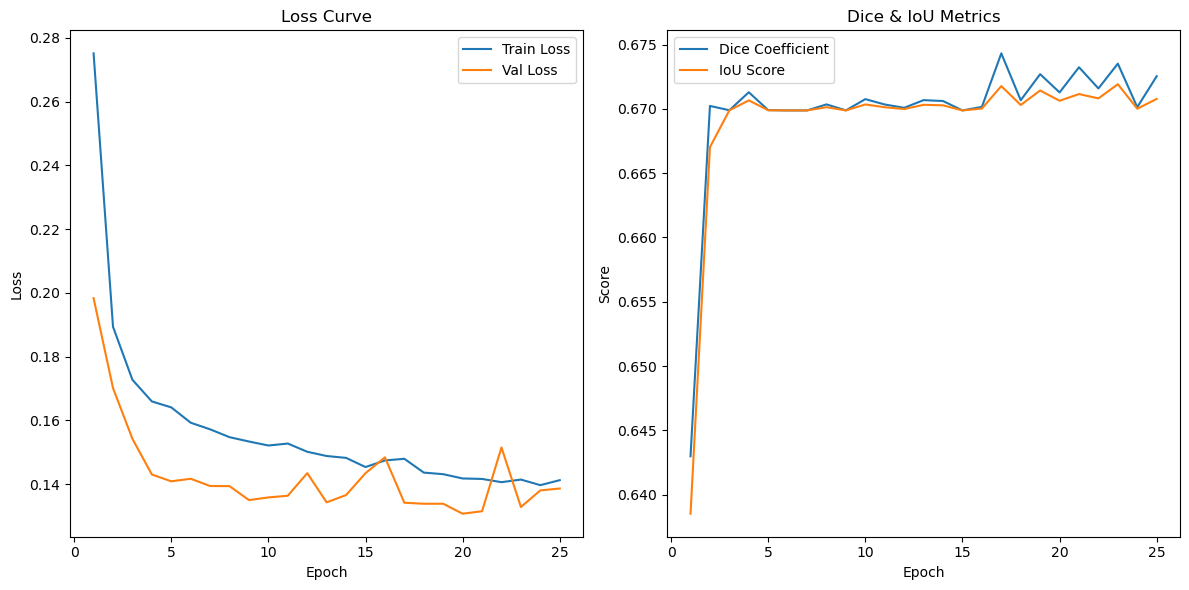

In [124]:
import torch
import torch.nn as nn
import torch.optim as optim
from tqdm import tqdm
import os
import matplotlib.pyplot as plt

# Set device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if torch.cuda.is_available():
    torch.cuda.empty_cache()
    print("Cleared CUDA cache after model initialization.")

# Model, loss, optimizer
model = UNet(in_channels=3, out_channels=1).to(device)
criterion = nn.BCEWithLogitsLoss()  # Binary segmentation
optimizer = optim.Adam(model.parameters(), lr=1e-4)

# Early stopping setup
best_val_loss = float('inf')
patience = 5
counter = 0
save_path = "best_model.pth"
num_epochs = 50

# Metric tracking
train_losses = []
val_losses = []
dice_scores = []
iou_scores = []

def compute_metrics(preds, targets):
    smooth = 1e-6
    preds = torch.sigmoid(preds)
    preds = (preds > 0.5).float()

    intersection = (preds * targets).sum(dim=(1, 2, 3))
    union = (preds + targets).sum(dim=(1, 2, 3)) - intersection
    dice = (2. * intersection + smooth) / (preds.sum(dim=(1,2,3)) + targets.sum(dim=(1,2,3)) + smooth)
    iou = (intersection + smooth) / (union + smooth)
    return dice.mean().item(), iou.mean().item()

for epoch in range(num_epochs):
    print(f"Epoch {epoch + 1}/{num_epochs}")

    # --- Training ---
    model.train()
    running_loss = 0.0
    for images, masks in tqdm(train_loader, desc="Training"):
        images, masks = images.to(device), masks.to(device)

        outputs = model(images)
        loss = criterion(outputs, masks)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)

    epoch_train_loss = running_loss / len(train_loader.dataset)
    train_losses.append(epoch_train_loss)
    print(f"Train Loss: {epoch_train_loss:.4f}")

    # --- Validation ---
    model.eval()
    val_loss = 0.0
    epoch_dice = 0.0
    epoch_iou = 0.0
    with torch.no_grad():
        for images, masks in tqdm(val_loader, desc="Validation"):
            images, masks = images.to(device), masks.to(device)
            outputs = model(images)
            loss = criterion(outputs, masks)
            val_loss += loss.item() * images.size(0)

            dice, iou = compute_metrics(outputs, masks)
            epoch_dice += dice * images.size(0)
            epoch_iou += iou * images.size(0)

    epoch_val_loss = val_loss / len(val_loader.dataset)
    epoch_dice /= len(val_loader.dataset)
    epoch_iou /= len(val_loader.dataset)

    val_losses.append(epoch_val_loss)
    dice_scores.append(epoch_dice)
    iou_scores.append(epoch_iou)

    print(f"Val Loss: {epoch_val_loss:.4f} | Dice: {epoch_dice:.4f} | IoU: {epoch_iou:.4f}")

    # --- Checkpoint ---
    if epoch_val_loss < best_val_loss:
        best_val_loss = epoch_val_loss
        counter = 0
        torch.save(model.state_dict(), save_path)
        print("✅ Best model saved.")
    else:
        counter += 1
        print(f"⏳ No improvement. Patience counter: {counter}/{patience}")
        if counter >= patience:
            print("⛔ Early stopping triggered.")
            break

# --- Visualization ---
epochs = range(1, len(train_losses) + 1)
plt.figure(figsize=(12, 6))

plt.subplot(1, 2, 1)
plt.plot(epochs, train_losses, label='Train Loss')
plt.plot(epochs, val_losses, label='Val Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Loss Curve')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(epochs, dice_scores, label='Dice Coefficient')
plt.plot(epochs, iou_scores, label='IoU Score')
plt.xlabel('Epoch')
plt.ylabel('Score')
plt.title('Dice & IoU Metrics')
plt.legend()

plt.tight_layout()
plt.savefig("training_metrics.png")
plt.show()


/tmp/ipykernel_1470/3425426822.py:12: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load("best_model.pth", map_location='cpu'))


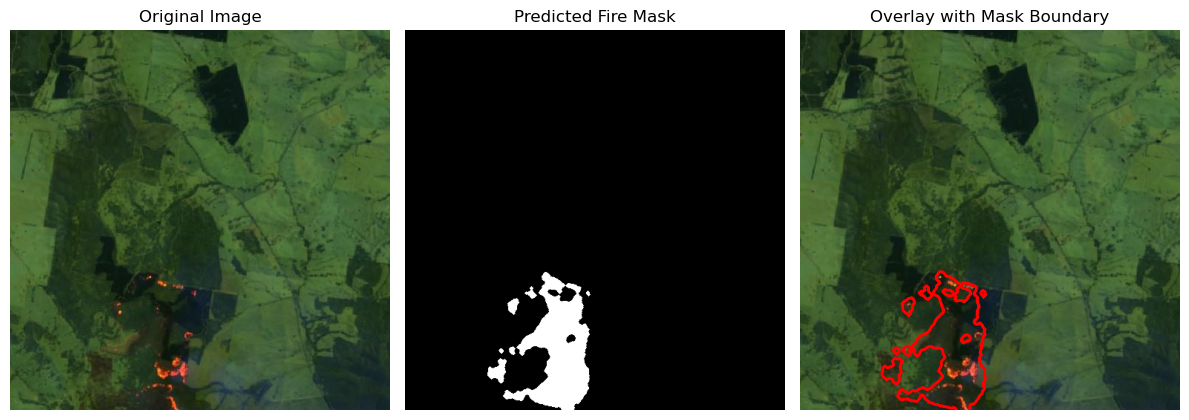

In [225]:
import torch
import numpy as np
import matplotlib.pyplot as plt
import random
from torchvision import transforms
from pathlib import Path
from PIL import Image
from skimage import measure

# Load model
model = UNet(in_channels=3, out_channels=1)
model.load_state_dict(torch.load("best_model.pth", map_location='cpu'))
model.eval()

# Use GPU if available
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(device)

# Path to val dataset
val_images_dir = Path("data/JPEGImages/val")
val_masks_dir = Path("data/SegmentationClass/val")

# Choose a random image
image_files = sorted(list(val_images_dir.glob("*.jpg")))  # or *.png depending on format
image_path = random.choice(image_files)
mask_path = val_masks_dir / (image_path.stem + ".png")

# Load and preprocess image
image = Image.open(image_path).convert("RGB")
mask = Image.open(mask_path).convert("L")

preprocess = transforms.Compose([
    transforms.Resize((512, 512)),
    transforms.ToTensor()
])

input_tensor = preprocess(image).unsqueeze(0).to(device)

# Inference
with torch.no_grad():
    output = model(input_tensor)
    pred_mask = torch.sigmoid(output).squeeze().cpu().numpy()
    pred_mask = (pred_mask > 0.5).astype(np.uint8)


selem_closing = morphology.disk(3) 
pred_mask = morphology.binary_closing(pred_mask, selem_closing).astype(np.uint8)


selem_opening = morphology.disk(2) # Creates a disk-shaped structuring element with radius 2
pred_mask = morphology.binary_opening(pred_mask, selem_opening).astype(np.uint8)

# Resize predicted mask to match original image size
pred_mask_resized = Image.fromarray(pred_mask * 255).resize(image.size, resample=Image.NEAREST)
pred_mask_resized = np.array(pred_mask_resized).astype(np.uint8)

# Prepare image for overlay
image_np = np.array(image)

# Find contours using skimage (contour coordinates are float, in (row, col) order)
contours = measure.find_contours(pred_mask_resized, level=0.5)

# Plot results
plt.figure(figsize=(12, 6))

plt.subplot(1, 3, 1)
plt.title("Original Image")
plt.imshow(image_np)
plt.axis('off')

plt.subplot(1, 3, 2)
plt.title("Predicted Fire Mask")
plt.imshow(pred_mask_resized, cmap="gray")
plt.axis('off')

plt.subplot(1, 3, 3)
plt.title("Overlay with Mask Boundary")
plt.imshow(image_np)
for contour in contours:
    plt.plot(contour[:, 1], contour[:, 0], linewidth=2, color='red')  # X=col, Y=row
plt.axis('off')

plt.tight_layout()
plt.show()


/tmp/ipykernel_1470/2113525053.py:10: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load("best_model.pth", map_location='cpu'))


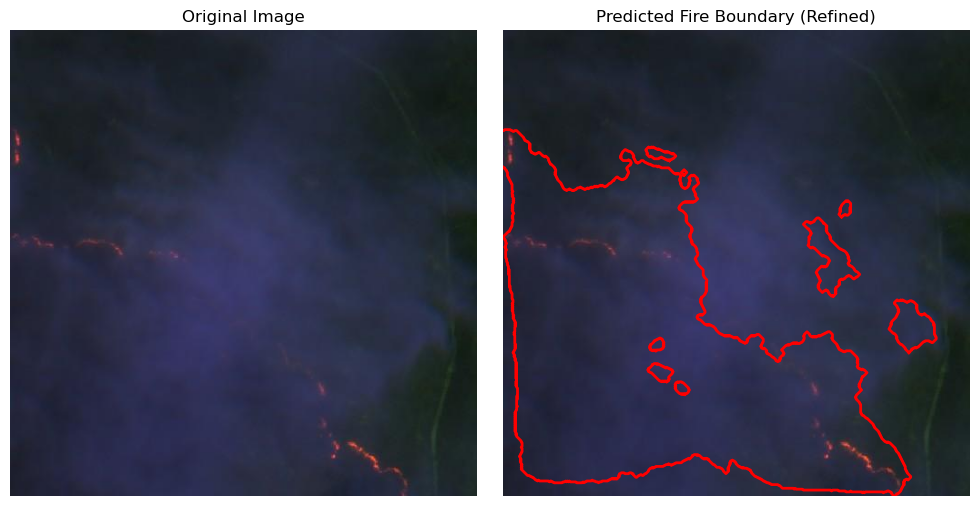

In [223]:
import torch
import numpy as np
import matplotlib.pyplot as plt
from torchvision import transforms
from pathlib import Path
from PIL import Image
from skimage import measure, morphology # Added morphology for refinement

model = UNet(in_channels=3, out_channels=1)
model.load_state_dict(torch.load("best_model.pth", map_location='cpu'))
model.eval()

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(device)

# ---- Set Path to a Single Image (no mask needed) ----
image_path = Path("data/JPEGImages/train/1868_Green_Valley_20200108.jpg")  # <-- change this to your image

# ---- Load and Preprocess Image ----
image = Image.open(image_path).convert("RGB")
original_size = image.size  # store for resizing back

preprocess = transforms.Compose([
    transforms.Resize((512, 512)),
    transforms.ToTensor()
])

input_tensor = preprocess(image).unsqueeze(0).to(device)

# ---- Inference ----
with torch.no_grad():
    output = model(input_tensor)
    pred_mask = torch.sigmoid(output).squeeze().cpu().numpy()
    pred_mask = (pred_mask > 0.5).astype(np.uint8) # Threshold to binary mask


selem_closing = morphology.disk(3) 
pred_mask = morphology.binary_closing(pred_mask, selem_closing).astype(np.uint8)


selem_opening = morphology.disk(2) # Creates a disk-shaped structuring element with radius 2
pred_mask = morphology.binary_opening(pred_mask, selem_opening).astype(np.uint8)


pred_mask_resized = Image.fromarray(pred_mask * 255).resize(original_size, resample=Image.NEAREST)
pred_mask_resized = np.array(pred_mask_resized).astype(np.uint8)

# ---- Overlay Predicted Mask Boundary ----
image_np = np.array(image)

contours = measure.find_contours(pred_mask_resized, level=0.5) # level=0.5 for binary masks (0s and 1s)

# ---- Plotting ----
plt.figure(figsize=(10, 5))

# Original Image
plt.subplot(1, 2, 1)
plt.title("Original Image")
plt.imshow(image_np)
plt.axis('off')

# Image with Predicted Fire Boundary (Refined)
plt.subplot(1, 2, 2)
plt.title("Predicted Fire Boundary (Refined)")
plt.imshow(image_np)
for contour in contours:
    # Plot contours. Note: find_contours returns (row, col) but plt.plot expects (x, y) = (col, row)
    plt.plot(contour[:, 1], contour[:, 0], linewidth=2, color='red')
plt.axis('off')

plt.tight_layout() # Adjusts subplot parameters for a tight layout
plt.show()